# Task-10 (Week-5)

**Date** :- (05-11-26)

**Dataset** :- 'Admission_Prediction.csv'

**Objective** :- Optimize complex machine learning models using Bayesian optimization, leveraging probabilistic models to identify optimal hyperparameter settings with minimal iterations.

In [5]:
# Import Library

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from skopt import BayesSearchCV
from skopt.space import Integer, Categorical


In [7]:
# Load the dataset

df = pd.read_csv("Admission_Prediction.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (1000, 18)


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Year,Application_Date,University_Name,region,Admission Status,Duration_Months,Dropout_Event,Dropout-free survival,Survival_Data_Note
0,104,317,104,2,4.5,4.0,8.47,0,0.57,2022,2022-01-03,Indian Institute of Technology Bombay,West,Rejected,36,0,0.536473,SIMULATED proxy derived from admission feature...
1,170,311,99,2,2.5,3.0,7.98,0,0.65,2022,2022-01-09,Indian Institute of Technology Delhi,North,Rejected,18,1,0.973000,SIMULATED proxy derived from admission feature...
2,138,316,100,2,1.5,3.0,8.16,1,0.71,2022,2022-01-12,Indian Institute of Technology Delhi,North,Rejected,33,0,0.597989,SIMULATED proxy derived from admission feature...
3,147,315,105,3,2.0,2.5,8.48,0,0.75,2022,2022-01-13,Indian Institute of Technology Delhi,North,Accepted,33,0,0.597989,SIMULATED proxy derived from admission feature...
4,117,299,102,3,4.0,3.5,8.62,0,0.56,2022,2022-01-14,Indian Institute of Technology Delhi,North,Rejected,28,1,0.734170,SIMULATED proxy derived from admission feature...


In [8]:
# dataset column list

print(df.columns.tolist())

['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit', 'Year', 'Application_Date', 'University_Name', 'region', 'Admission Status', 'Duration_Months', 'Dropout_Event', 'Dropout-free survival', 'Survival_Data_Note']


In [13]:
# Data Preprocessing

df = df.drop(
    columns=[
        "Serial No.",
        "Chance of Admit",
        "Application_Date",
        "Year",
        "Duration_Months",
        "Dropout_Event",
        "Dropout-free survival",
        "Survival_Data_Note"
    ],
    errors="ignore"
)

# Clean the target column
df["Admission Status"] = (
    df["Admission Status"]
    .astype(str)
    .str.strip()
    .str.title()
)

df = df[
    df["Admission Status"].isin(["Accepted", "Rejected"])
].copy()

# Separate independent features and target variable:

X = df.drop("Admission Status", axis=1)

y = df["Admission Status"].map({
    "Rejected": 0,
    "Accepted": 1
})

print("Features Shape:", X.shape)
print("Target Distribution:")
print(y.value_counts())

Features Shape: (1000, 9)
Target Distribution:
Admission Status
0    565
1    435
Name: count, dtype: int64


In [14]:
# Identify Numerical and Categorical Features

numeric_features = [
    "GRE Score",
    "TOEFL Score",
    "University Rating",
    "SOP",
    "LOR",
    "CGPA",
    "Research"
]

categorical_features = [
    "University_Name",
    "region"
]

In [15]:
# Create Preprocessing Pipeline

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [16]:
# Split the Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (800, 9)
Testing Data: (200, 9)


In [18]:
# Create the Machine Learning Pipeline

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

# Define Hyperparameter Search Spac

search_space = {
    "model__n_estimators": Integer(100, 500),

    "model__max_depth": Integer(3, 30),

    "model__min_samples_split": Integer(2, 20),

    "model__min_samples_leaf": Integer(1, 10),

    "model__max_features": Categorical(
        ["sqrt", "log2", None]
    ),

    "model__bootstrap": Categorical(
        [True, False]
    ),

    "model__class_weight": Categorical(
        [None, "balanced"]
    )
}

In [23]:
# Apply Bayesian Optimization

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

bayes_search = BayesSearchCV(
    estimator=pipeline,

    search_spaces=search_space,

    n_iter=30,

    scoring="f1_macro",

    cv=cv,

    n_jobs=-1,

    random_state=42,

    verbose=1,

    refit=True
)

In [24]:
# Train and Optimize the Model
bayes_search.fit(X_train, y_train)

# Display the Best Hyperparameters
print("Best Hyperparameters:")

print(bayes_search.best_params_)

print("\nBest Cross-Validation F1 Score:")

print(bayes_search.best_score_)

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fi

In [25]:
# Evaluate the Optimized Model

best_model = bayes_search.best_estimator_

y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("Optimized Random Forest Performance")

print("Accuracy:", accuracy)

print("Precision:", precision)

print("Recall:", recall)

print("F1 Score:", f1)

Optimized Random Forest Performance
Accuracy: 0.665
Precision: 0.625
Recall: 0.5747126436781609
F1 Score: 0.5988023952095808


              precision    recall  f1-score   support

    Rejected       0.69      0.73      0.71       113
    Accepted       0.62      0.57      0.60        87

    accuracy                           0.67       200
   macro avg       0.66      0.65      0.66       200
weighted avg       0.66      0.67      0.66       200



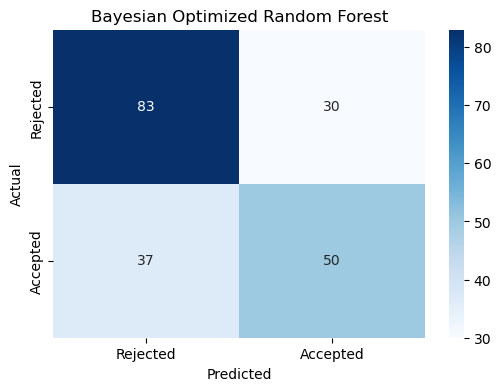

In [26]:
# Generate Classification Report
print(classification_report(
    y_test,
    y_pred,
    target_names=["Rejected", "Accepted"]
))

# Visualize the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rejected", "Accepted"],
    yticklabels=["Rejected", "Accepted"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Bayesian Optimized Random Forest")

plt.show()

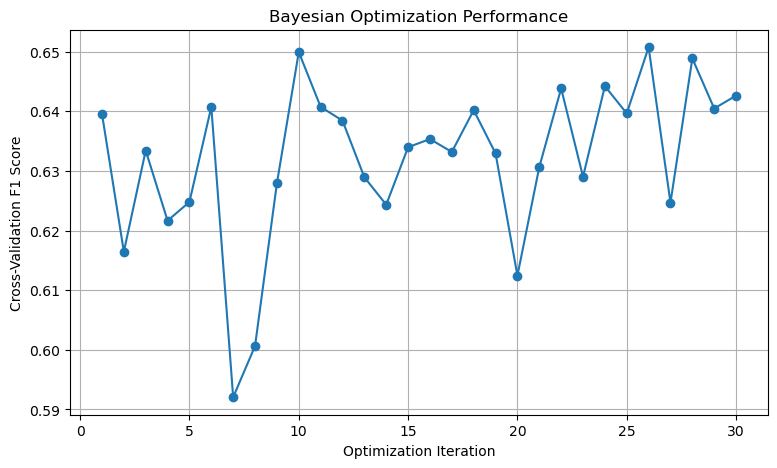

In [27]:
# Visualize Bayesian Optimization Results

iterations = range(
    1,
    len(bayes_search.cv_results_["mean_test_score"]) + 1
)

scores = bayes_search.cv_results_["mean_test_score"]

plt.figure(figsize=(9, 5))

plt.plot(
    iterations,
    scores,
    marker="o"
)

plt.xlabel("Optimization Iteration")

plt.ylabel("Cross-Validation F1 Score")

plt.title("Bayesian Optimization Performance")

plt.grid(True)

plt.show()